# PS8 interim analysis: IEEE-CIS Fraud Detection
Genesis Joseph & Tatenda, CIS 731. The data is the original Kaggle files in `../data/` (not committed). All metrics here are **advisory** (validation period only); the test period is held out for the final evaluation.

In [1]:
import json, sys
sys.path.insert(0, '.')
import ps8_lib as L
out = L.run_all()
print('done')

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


done


## Data card (verifies the row and column counts used in Q2)

In [2]:
print(json.dumps(out['data_card'], indent=2))

{
  "tables": {
    "train_transaction.csv": {
      "rows": 590540,
      "columns": 394,
      "bytes": 683351067,
      "sha256": "3a5c83ab6b3cc13dcabe5ffa9f522307fd5f7f7b6e6f6a60c32284ca6283d642"
    },
    "train_identity.csv": {
      "rows": 144233,
      "columns": 41,
      "bytes": 26529680,
      "sha256": "b63c725d8377be90a995268d97f347c17d456b95db45807adcf9f59cd603c37c"
    },
    "test_transaction.csv": {
      "rows": 506691,
      "columns": 393,
      "bytes": 613194934,
      "sha256": "2a8e51f1d335a86025d2b7f45beb9b78d0ab1edd726ef531d8b71a8a0065c011"
    },
    "test_identity.csv": {
      "rows": 141907,
      "columns": 41,
      "bytes": 25797161,
      "sha256": "3e5978cb13ca5e72f52babc4349ae0125e14b87ca8bfabe952ab67bb4ff1e10b"
    }
  },
  "total_rows": 1383371,
  "train_fraud_count": 20663,
  "train_fraud_rate": 0.03499000914417313,
  "identity_coverage": 0.2442391709283029,
  "transaction_dt_days": 181.99920138888888,
  "validity_checks": {
    "TransactionID_

## Fig. 1: Missingness by feature group

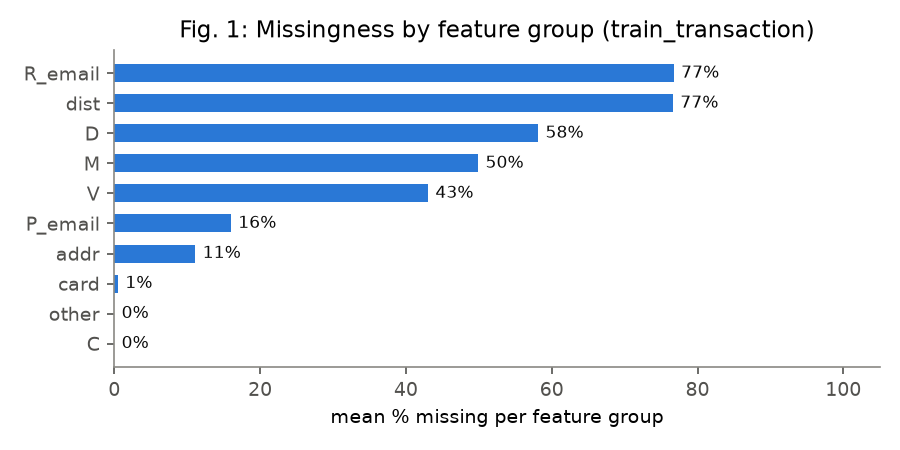

{'C': 0.0, 'other': 0.0, 'card': 0.0051, 'addr': 0.1113, 'P_email': 0.1599, 'V': 0.4304, 'M': 0.4992, 'D': 0.5815, 'dist': 0.7664, 'R_email': 0.7675}


In [3]:
from IPython.display import Image, display
display(Image('figures/fig1_missingness.png'))
print(out['fig1_missingness'])

## Fig. 2: Weekly fraud rate with 95% Wilson intervals (cohort drift)

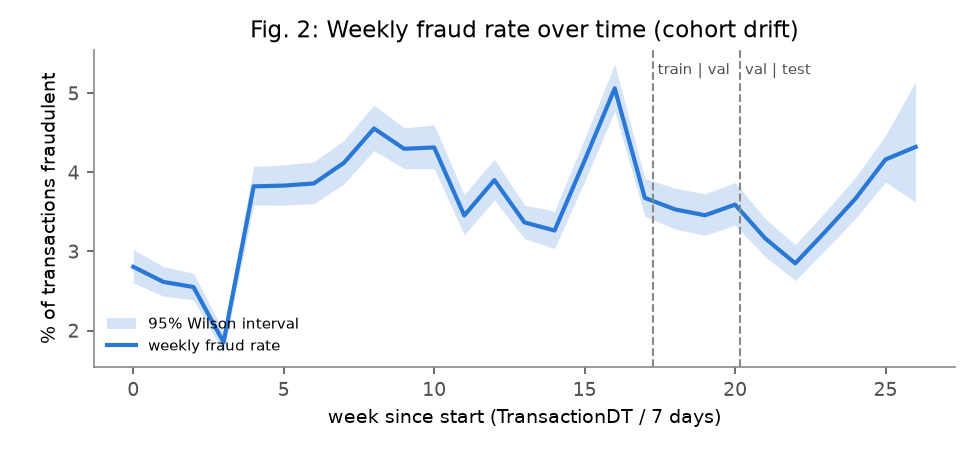

{'weeks': 27, 'min_rate': 0.018522992671337682, 'max_rate': 0.05061181735942485, 'first_week_rate': 0.028055438891222174, 'last_week_rate': 0.043209876543209874}


In [4]:
display(Image('figures/fig2_drift.png'))
print(out['fig2_drift'])

## Fig. 3: Transaction amount by class

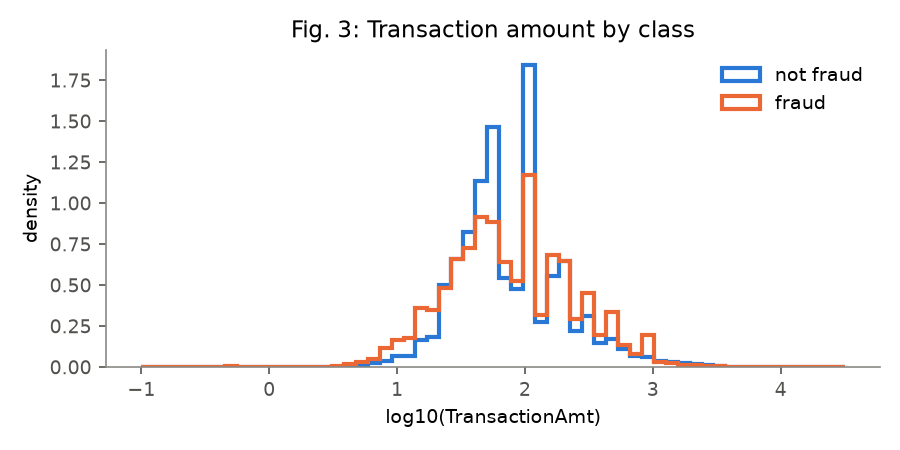

{'median_amt_not_fraud': 68.5, 'median_amt_fraud': 75.0}


In [5]:
display(Image('figures/fig3_amount.png'))
print(out['fig3_amount'])

## Fig. 4: UMAP sensitivity sweep (n_neighbors × min_dist, fixed random_state)

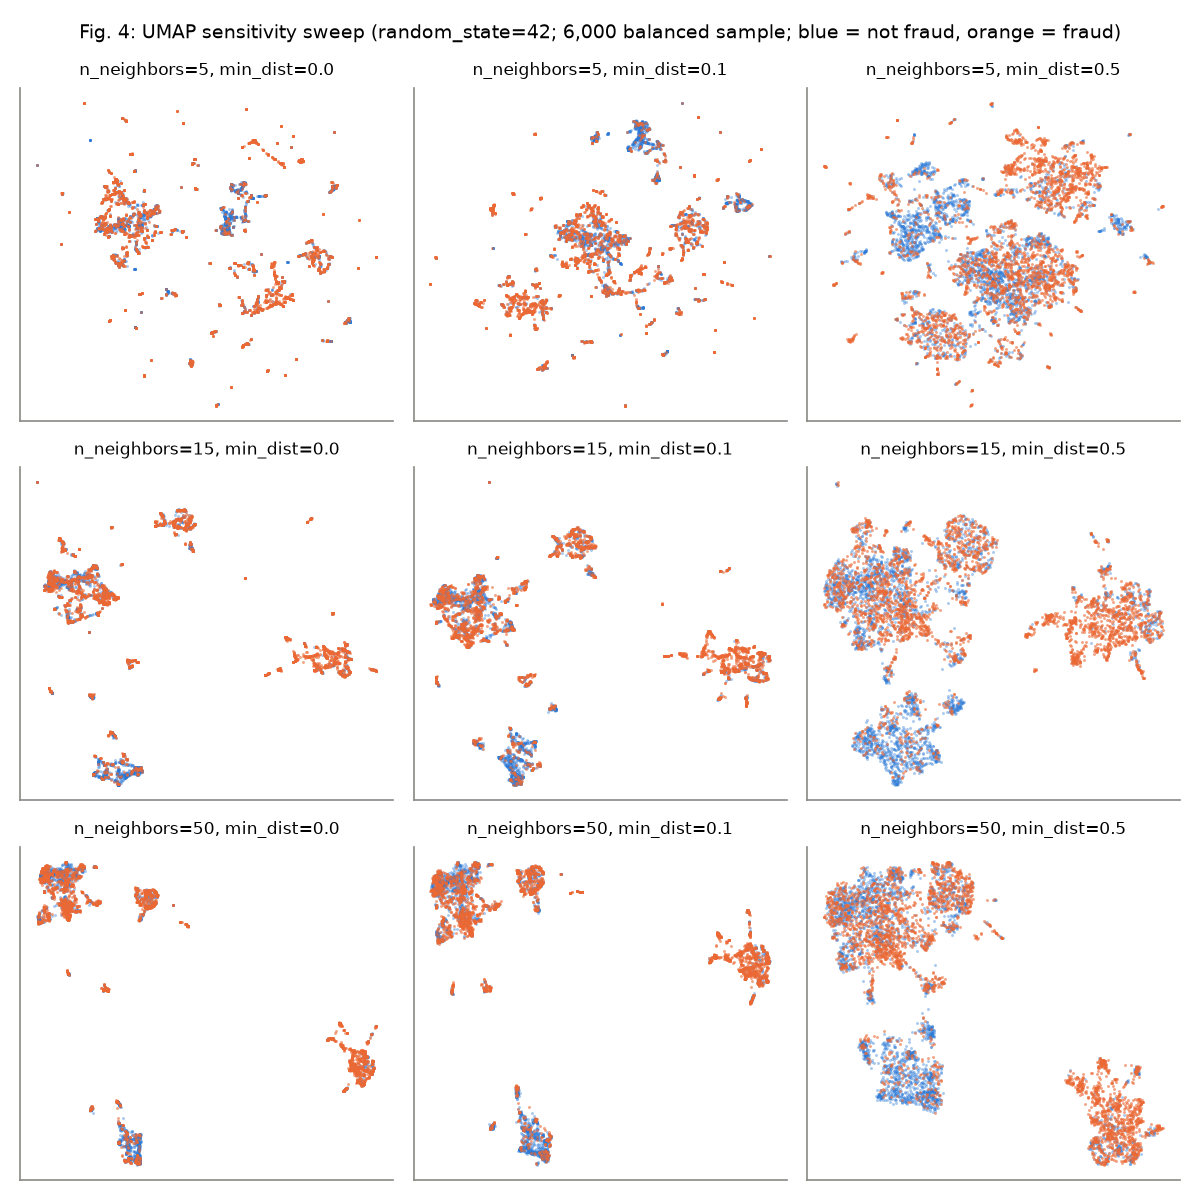

{'sample_size': 6000, 'n_features': 208, 'random_state': 42, 'n_neighbors': [5, 15, 50], 'min_dist': [0.0, 0.1, 0.5]}


In [6]:
display(Image('figures/fig4_umap_sweep.png'))
print(out['fig4_umap'])

## Naive baselines (advisory, validation period)

In [7]:
print(json.dumps(out['baselines'], indent=2))

{
  "split": {
    "train_rows": 413378,
    "val_rows": 59053,
    "test_rows_held_out": 118109,
    "val_fraud_rate": 0.03490085177721708
  },
  "majority_class": {
    "pr_auc": 0.03490085177721708,
    "roc_auc": 0.5,
    "note": "always predicts not-fraud; PR-AUC equals the fraud rate"
  },
  "logistic_regression": {
    "pr_auc": 0.3794528103886848,
    "roc_auc": 0.8445642310838898,
    "features": 211,
    "class_weight": "balanced"
  },
  "grading_eligible": false
}


## Component versions (project manifest)

In [8]:
print(json.dumps(out['manifest'], indent=2))

{
  "python": "3.12.1",
  "platform": "macOS-26.6.2-arm64-arm-64bit",
  "packages": {
    "pandas": "3.1.1",
    "numpy": "2.5.3",
    "scikit-learn": "1.9.1",
    "umap-learn": "0.5.12",
    "matplotlib": "3.11.2",
    "xgboost": "not installed",
    "kaggle": "2.2.5"
  },
  "random_state": 42,
  "source": "Kaggle competition ieee-fraud-detection (IEEE-CIS / Vesta), original files, downloaded via Kaggle API"
}
